In [1]:

import random
import numpy as np
import pandas as pd
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATA_DIR = "/kaggle/input/datasets/rpghost/scaffold-regression"
OUTPUT_DIR = "/kaggle/working/chemberta_regression"
os.makedirs(OUTPUT_DIR, exist_ok=True)

train_df = pd.read_csv(f"{DATA_DIR}/train_regression.csv")
train_df["smiles"] = train_df["smiles"].str.split(";").str[0].str.split(" ").str[0]
val_df = pd.read_csv(f"{DATA_DIR}/val_regression.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test_regression.csv")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"{name}: {df.shape}")
    print(df.columns.tolist())
    assert df["smiles"].notna().all()
    assert df["median_pIC50"].notna().all()

Using device: cuda
Train: (7402, 3)
['inchi_key', 'smiles', 'median_pIC50']
Validation: (948, 3)
['inchi_key', 'smiles', 'median_pIC50']
Test: (1941, 3)
['inchi_key', 'smiles', 'median_pIC50']


In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU capability:", torch.cuda.get_device_capability(0))
print("Supported architectures:", torch.cuda.get_arch_list())

PyTorch: 2.11.0+cu128
CUDA version: 12.8
GPU: Tesla T4
GPU capability: (7, 5)
Supported architectures: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


In [3]:
import torch

device = torch.device("cuda")

# Test basic GPU tensor operations
a = torch.randn(1024, 1024, device=device)
b = torch.randn(1024, 1024, device=device)

c = a @ b
torch.cuda.synchronize()

print("Matrix multiplication succeeded!")
print("Result finite:", torch.isfinite(c).all().item())

Matrix multiplication succeeded!
Result finite: True


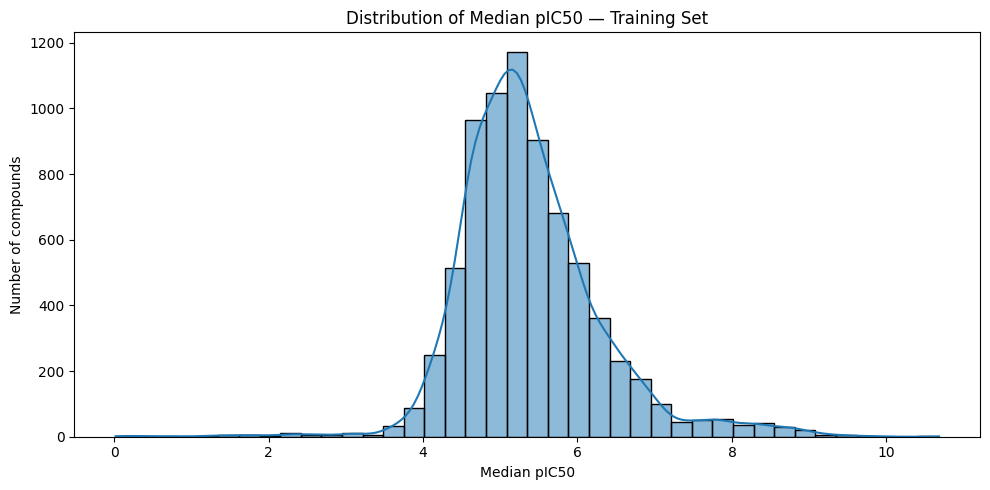

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load regression training data
DATA_DIR = "/kaggle/input/datasets/rpghost/scaffold-regression"

train_df = pd.read_csv(f"{DATA_DIR}/train_regression.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val_regression.csv")

# Plot target distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="median_pIC50",
    bins=40,
    kde=True
)

plt.xlabel("Median pIC50")
plt.ylabel("Number of compounds")
plt.title("Distribution of Median pIC50 — Training Set")
plt.tight_layout()
plt.show()

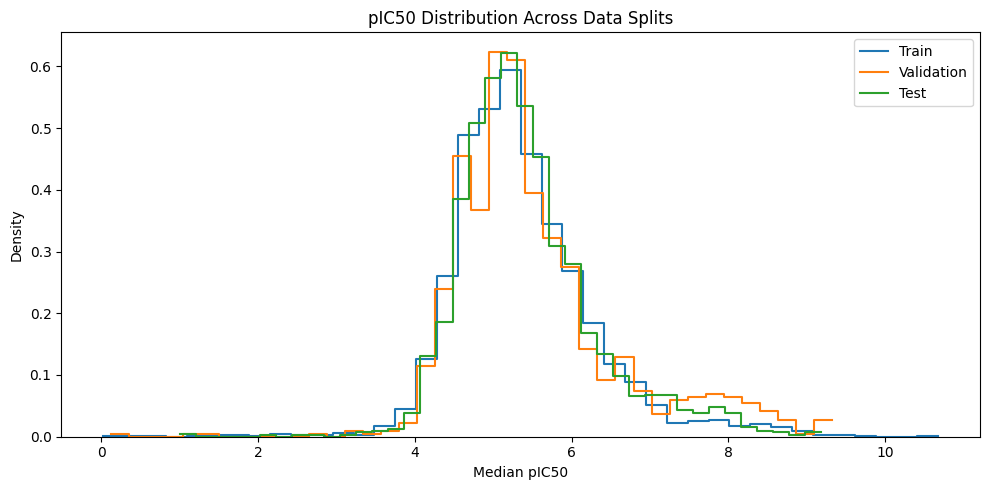

In [5]:
test_df = pd.read_csv(f"{DATA_DIR}/test_regression.csv")

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["median_pIC50"],
    bins=40,
    stat="density",
    element="step",
    fill=False,
    label="Train"
)

sns.histplot(
    val_df["median_pIC50"],
    bins=40,
    stat="density",
    element="step",
    fill=False,
    label="Validation"
)

sns.histplot(
    test_df["median_pIC50"],
    bins=40,
    stat="density",
    element="step",
    fill=False,
    label="Test"
)

plt.xlabel("Median pIC50")
plt.ylabel("Density")
plt.title("pIC50 Distribution Across Data Splits")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
print("Target distribution summary:")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    y = df["median_pIC50"].dropna()

    print(f"\n{name}")
    print(f"Count:  {len(y)}")
    print(f"Mean:   {y.mean():.3f}")
    print(f"Std:    {y.std():.3f}")
    print(f"Min:    {y.min():.3f}")
    print(f"Median: {y.median():.3f}")
    print(f"Max:    {y.max():.3f}")

Target distribution summary:

Train
Count:  7402
Mean:   5.380
Std:    0.918
Min:    0.020
Median: 5.260
Max:    10.678

Validation
Count:  948
Mean:   5.534
Std:    1.088
Min:    0.120
Median: 5.291
Max:    9.319

Test
Count:  1941
Mean:   5.429
Std:    0.882
Min:    1.000
Median: 5.276
Max:    9.187


In [7]:
MODEL_NAME = "DeepChem/ChemBERTa-100M-MLM"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def clean_smiles(s):
    return str(s).split(";")[0].split(" ")[0].strip()

for df in (train_df, val_df, test_df):
    df["smiles"] = df["smiles"].map(clean_smiles)
X_train = train_df["smiles"].astype(str).tolist()
y_train = train_df["median_pIC50"].astype(float).tolist()

X_val = val_df["smiles"].astype(str).tolist()
y_val = val_df["median_pIC50"].astype(float).tolist()

X_test = test_df["smiles"].astype(str).tolist()
y_test = test_df["median_pIC50"].astype(float).tolist()

class ChemBERTaRegressionDataset(Dataset):
    def __init__(self, smiles, targets):
        self.smiles = smiles
        self.targets = targets

    def __len__(self):
        return len(self.smiles)

    def __getitem__(self, idx):
        return self.smiles[idx], self.targets[idx]


def collate_fn(batch):
    smiles = [item[0] for item in batch]

    targets = torch.tensor(
        [item[1] for item in batch],
        dtype=torch.float32
    ).unsqueeze(1)

    inputs = tokenizer(
        smiles,
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )

    return inputs["input_ids"], inputs["attention_mask"], targets


train_dataset = ChemBERTaRegressionDataset(X_train, y_train)
val_dataset = ChemBERTaRegressionDataset(X_val, y_val)
test_dataset = ChemBERTaRegressionDataset(X_test, y_test)

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 232
Validation batches: 30
Test batches: 61


In [8]:
import torch
import torch.nn as nn
from transformers import AutoModel

# Force CPU execution
# device = torch.device("cpu")
# print("Training device:", device)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

class ChemBERTaRegressor(nn.Module):
    def __init__(self):
        super().__init__()

        self.chemberta = AutoModel.from_pretrained(MODEL_NAME)
        hidden_size = self.chemberta.config.hidden_size

        self.regressor = nn.Sequential(
            nn.Linear(hidden_size, 512),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = outputs.last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden_states.dtype)

        masked_hidden = hidden_states * mask
        summed = masked_hidden.sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1)

        pooled = summed / counts
        return self.regressor(pooled)


# Create a fresh model on the CPU
model = ChemBERTaRegressor().to(device)

optimizer = torch.optim.AdamW(
    [
        {"params": model.chemberta.parameters(), "lr": 2e-5},
        {"params": model.regressor.parameters(), "lr": 1e-3}
    ],
    weight_decay=1e-4
)

criterion = nn.MSELoss()

print("Actual model device:", next(model.parameters()).device)

Training device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: DeepChem/ChemBERTa-100M-MLM
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Actual model device: cuda:0


In [9]:
# print("PyTorch:", torch.__version__)
# print("CUDA version:", torch.version.cuda)
# print("GPU:", torch.cuda.get_device_name(0))
# print("GPU available:", torch.cuda.is_available())

In [10]:
NUM_EPOCHS = 50
PATIENCE = 2

best_val_loss = float("inf")
patience_counter = 0

BEST_CHECKPOINT = f"{OUTPUT_DIR}/best_checkpoint_seed123.pt"
LATEST_CHECKPOINT = f"{OUTPUT_DIR}/latest_checkpoint_seed123.pt"

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss_sum = 0.0

    for input_ids, attention_mask, targets in tqdm(
        train_loader, desc=f"Epoch {epoch + 1} training"
    ):
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(input_ids, attention_mask)
        # torch.cuda.synchronize()
        loss = criterion(predictions, targets)
        # torch.cuda.synchronize()

        loss.backward()
        # torch.cuda.synchronize()
        optimizer.step()
        # torch.cuda.synchronize()

        train_loss_sum += loss.item() * len(targets)

    train_loss = train_loss_sum / len(train_dataset)

    model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for input_ids, attention_mask, targets in val_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            targets = targets.to(device)

            predictions = model(input_ids, attention_mask)
            loss = criterion(predictions, targets)

            val_loss_sum += loss.item() * len(targets)

    val_loss = val_loss_sum / len(val_dataset)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train MSE: {train_loss:.4f} | "
        f"Validation MSE: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "seed": SEED
        }, BEST_CHECKPOINT)

        print("Best checkpoint saved.")

    else:
        patience_counter += 1

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "seed": SEED
    }, LATEST_CHECKPOINT)

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

Epoch 1 training:   0%|          | 0/232 [00:00<?, ?it/s]

Epoch 01 | Train MSE: 1.3811 | Validation MSE: 1.0516
Best checkpoint saved.


Epoch 2 training:   0%|          | 0/232 [00:00<?, ?it/s]

Epoch 02 | Train MSE: 0.6616 | Validation MSE: 0.9432
Best checkpoint saved.


Epoch 3 training:   0%|          | 0/232 [00:00<?, ?it/s]

...

Epoch 08 | Train MSE: 0.2746 | Validation MSE: 0.6799
Best checkpoint saved.


Epoch 9 training:   0%|          | 0/232 [00:00<?, ?it/s]

Epoch 09 | Train MSE: 0.2563 | Validation MSE: 0.7910


Epoch 10 training:   0%|          | 0/232 [00:00<?, ?it/s]

Epoch 10 | Train MSE: 0.2369 | Validation MSE: 0.9773
Early stopping.


In [11]:
# import torch

# # Inspect batch 29
# for i, batch in enumerate(train_loader):
#     if i == 29:
#         input_ids, attention_mask, targets = batch
#         break

# print("Batch shape:", input_ids.shape)
# print("Token IDs:", input_ids.min().item(), input_ids.max().item())

# embedding_size = model.chemberta.get_input_embeddings().num_embeddings
# print("Embedding size:", embedding_size)

# print(
#     "Invalid token IDs:",
#     ((input_ids < 0) | (input_ids >= embedding_size)).sum().item()
# )

# print("Targets finite:", torch.isfinite(targets).all().item())
# print("Target min/max:", targets.min().item(), targets.max().item())
# print("Mask values:", torch.unique(attention_mask))

# # Check whether the batch contains unusually long sequences
# print("Sequence lengths:", attention_mask.sum(dim=1).tolist())

In [12]:
# cpu_model = model.to("cpu")
# cpu_model.eval()

# with torch.no_grad():
#     cpu_predictions = cpu_model(input_ids, attention_mask)

# print("CPU forward pass succeeded:", cpu_predictions.shape)
# print("Finite predictions:", torch.isfinite(cpu_predictions).all().item())

In [13]:
# import torch

# model = model.to("cuda")
# model.eval()

# # Retrieve batch 29
# for i, batch in enumerate(train_loader):
#     if i == 29:
#         input_ids, attention_mask, targets = batch
#         break

# input_ids = input_ids.to("cuda")
# attention_mask = attention_mask.to("cuda")

# with torch.no_grad():
#     output = model.chemberta(
#         input_ids=input_ids,
#         attention_mask=attention_mask
#     )
#     torch.cuda.synchronize()

# print("GPU encoder succeeded:", output.last_hidden_state.shape)

# with torch.no_grad():
#     predictions = model(input_ids, attention_mask)
#     torch.cuda.synchronize()

# print("GPU model succeeded:", predictions.shape)

In [14]:
# model.train()

# targets = targets.to("cuda").float()
# optimizer.zero_grad(set_to_none=True)

# predictions = model(input_ids, attention_mask)
# loss = criterion(predictions, targets)

# print("Loss:", loss.item())

# loss.backward()
# torch.cuda.synchronize()
# print("Backward succeeded")

# optimizer.step()
# torch.cuda.synchronize()
# print("Optimizer succeeded")

In [15]:
# import torch
# from tqdm.auto import tqdm

# NUM_EPOCHS = 50
# PATIENCE = 7

# best_val_loss = float("inf")
# patience_counter = 0

# BEST_CHECKPOINT = f"{OUTPUT_DIR}/best_checkpoint_seed123.pt"
# LATEST_CHECKPOINT = f"{OUTPUT_DIR}/latest_checkpoint_seed123.pt"

# for epoch in range(NUM_EPOCHS):
#     model.train()
#     train_loss_sum = 0.0

#     for batch_idx, (input_ids, attention_mask, targets) in enumerate(
#         tqdm(train_loader, desc=f"Epoch {epoch + 1} training")
#     ):
#         try:
#             input_ids = input_ids.to(device)
#             attention_mask = attention_mask.to(device)
#             targets = targets.to(device).float()

#             optimizer.zero_grad(set_to_none=True)

#             print(
#                 f"Epoch {epoch + 1}, batch {batch_idx}: forward",
#                 flush=True
#             )
#             predictions = model(input_ids, attention_mask)
#             torch.cuda.synchronize()

#             loss = criterion(predictions, targets)
#             torch.cuda.synchronize()

#             print(
#                 f"Epoch {epoch + 1}, batch {batch_idx}: backward",
#                 flush=True
#             )
#             loss.backward()
#             torch.cuda.synchronize()

#             print(
#                 f"Epoch {epoch + 1}, batch {batch_idx}: optimizer",
#                 flush=True
#             )
#             optimizer.step()
#             torch.cuda.synchronize()

#             train_loss_sum += loss.item() * len(targets)

#         except Exception as e:
#             print(
#                 f"\nFAILED at epoch {epoch + 1}, batch {batch_idx}",
#                 flush=True
#             )
#             print(repr(e), flush=True)
#             raise

#     train_loss = train_loss_sum / len(train_dataset)

#     model.eval()
#     val_loss_sum = 0.0

#     with torch.no_grad():
#         for input_ids, attention_mask, targets in val_loader:
#             input_ids = input_ids.to(device)
#             attention_mask = attention_mask.to(device)
#             targets = targets.to(device).float()

#             predictions = model(input_ids, attention_mask)
#             loss = criterion(predictions, targets)
#             torch.cuda.synchronize()

#             val_loss_sum += loss.item() * len(targets)

#     val_loss = val_loss_sum / len(val_dataset)

#     print(
#         f"Epoch {epoch + 1:02d} | "
#         f"Train MSE: {train_loss:.4f} | "
#         f"Validation MSE: {val_loss:.4f}"
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         patience_counter = 0

#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": model.state_dict(),
#             "optimizer_state_dict": optimizer.state_dict(),
#             "best_val_loss": best_val_loss,
#             "seed": SEED
#         }, BEST_CHECKPOINT)

#         print("Best checkpoint saved.")

#     else:
#         patience_counter += 1

#     torch.save({
#         "epoch": epoch + 1,
#         "model_state_dict": model.state_dict(),
#         "optimizer_state_dict": optimizer.state_dict(),
#         "best_val_loss": best_val_loss,
#         "seed": SEED
#     }, LATEST_CHECKPOINT)

#     if patience_counter >= PATIENCE:
#         print("Early stopping.")
#         break

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, spearmanr

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


def predict_loader(loader):
    predictions = []

    with torch.no_grad():
        for input_ids, attention_mask, _ in loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)

            output = model(input_ids, attention_mask)
            predictions.extend(output.squeeze(1).cpu().numpy())

    return np.asarray(predictions)


val_predictions = predict_loader(val_loader)
test_predictions = predict_loader(test_loader)

val_results = val_df[["inchi_key", "smiles", "median_pIC50"]].copy()
val_results = val_results.rename(
    columns={"median_pIC50": "actual_pIC50"}
)
val_results["predicted_pIC50"] = val_predictions

test_results = test_df[["inchi_key", "smiles", "median_pIC50"]].copy()
test_results = test_results.rename(
    columns={"median_pIC50": "actual_pIC50"}
)
test_results["predicted_pIC50"] = test_predictions


def regression_metrics(results, split_name):
    actual = results["actual_pIC50"].to_numpy()
    predicted = results["predicted_pIC50"].to_numpy()

    return {
        "Split": split_name,
        "N": len(results),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "R2": r2_score(actual, predicted),
        "Pearson_r": pearsonr(actual, predicted).statistic,
        "Spearman_r": spearmanr(actual, predicted).statistic
    }


metrics_df = pd.DataFrame([
    regression_metrics(val_results, "Validation"),
    regression_metrics(test_results, "Test")
])

display(metrics_df.round(4))

val_results.to_csv(
    f"{OUTPUT_DIR}/val_evaluated_predictions.csv", index=False
)
test_results.to_csv(
    f"{OUTPUT_DIR}/test_evaluated_predictions.csv", index=False
)
metrics_df.to_csv(
    f"{OUTPUT_DIR}/regression_metrics.csv", index=False
)

print("Saved ChemBERTa regression predictions and metrics.")

,Split,N,RMSE,MAE,R2,Pearson_r,Spearman_r
0,Validation,948,0.8245,0.5750,0.4254,0.6794,0.6388
1,Test,1941,0.7105,0.5226,0.3508,0.6203,0.5630


Saved ChemBERTa regression predictions and metrics.
